# Testing Dense Optical Flow

## 1. Implement 2D Points Projection model over 3 DOF sensor motion

In [33]:
import matplotlib.pyplot as plt
import numpy as np

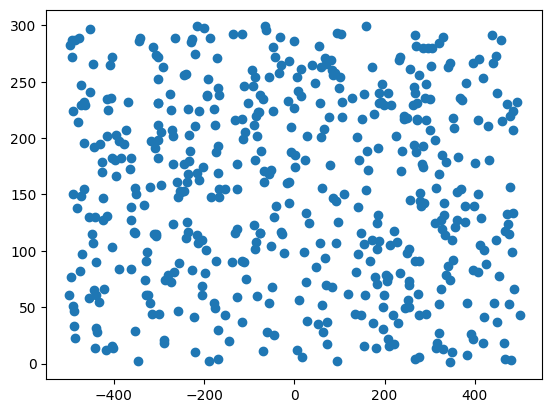

In [34]:
# Generating random points over the space
N_points = 500

y_min = 0
y_max = 300
x_min = -500
x_max = 500

x_s1 = np.random.randint(x_min,x_max, size=(N_points,1))
y_s1 = np.random.randint(y_min,y_max, size=(N_points,1))
p_s1 = np.hstack((x_s1, y_s1))


plt.figure()
plt.scatter(p_s1[:,0], p_s1[:,1])

plt.show()


In [35]:
def draw_axes(T, is_estimated=False, frame="O"):
    x = np.array([1, 0, 1])
    y = np.array([0, 1, 1])

    Origin = np.array([0, 0, 1])
    
    Origin_new = T @ Origin.T
    x_new = T @ x.T - Origin_new
    y_new = T @ y.T - Origin_new

    c_x = 'red'
    c_y = 'green'
    c_origin = 'black'
    alpha = 1.0

    if is_estimated:
        alpha = 0.4
    
    plt.text(Origin_new[0]-1, Origin_new[1]-1, frame)
    plt.quiver(Origin_new[0], Origin_new[1], x_new[0], x_new[1], scale=10, color=(c_x,alpha), angles='uv')
    plt.quiver(Origin_new[0], Origin_new[1], y_new[0], y_new[1], scale=10, color=(c_y, alpha), angles='uv')
    plt.scatter(Origin_new[0], Origin_new[1], c=(c_origin, alpha))

(500, 3)


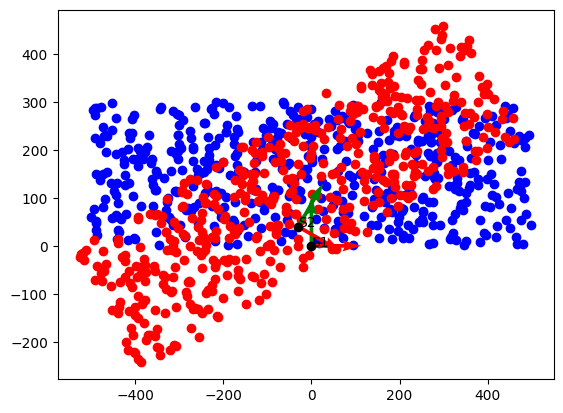

In [36]:
dx = -30
dy =  40
dth = -30 * np.pi / 180

T_s1_s2 = np.array([[np.cos(dth), -np.sin(dth), dx], [np.sin(dth), np.cos(dth), dy], [0, 0, 1]])
T_s2_s1 = np.linalg.inv(T_s1_s2)

p_s1_tilde = np.hstack([p_s1, np.ones((len(p_s1), 1))])  # (10, 3)
p_s2_tilde = (T_s2_s1 @ p_s1_tilde.T).T                  # (10, 3)
p_s2 = p_s2_tilde[:, :2]                                  # (10, 2)

print(p_s2_tilde.shape)

plt.figure()

# plt.xlim(0,50)
# plt.ylim(0,50)
plt.scatter(p_s1[:,0], p_s1[:,1], c='blue')
plt.scatter(p_s2[:,0], p_s2[:,1], c='red')

draw_axes(np.eye(3), frame="S1")
draw_axes(T_s1_s2, frame="S2")


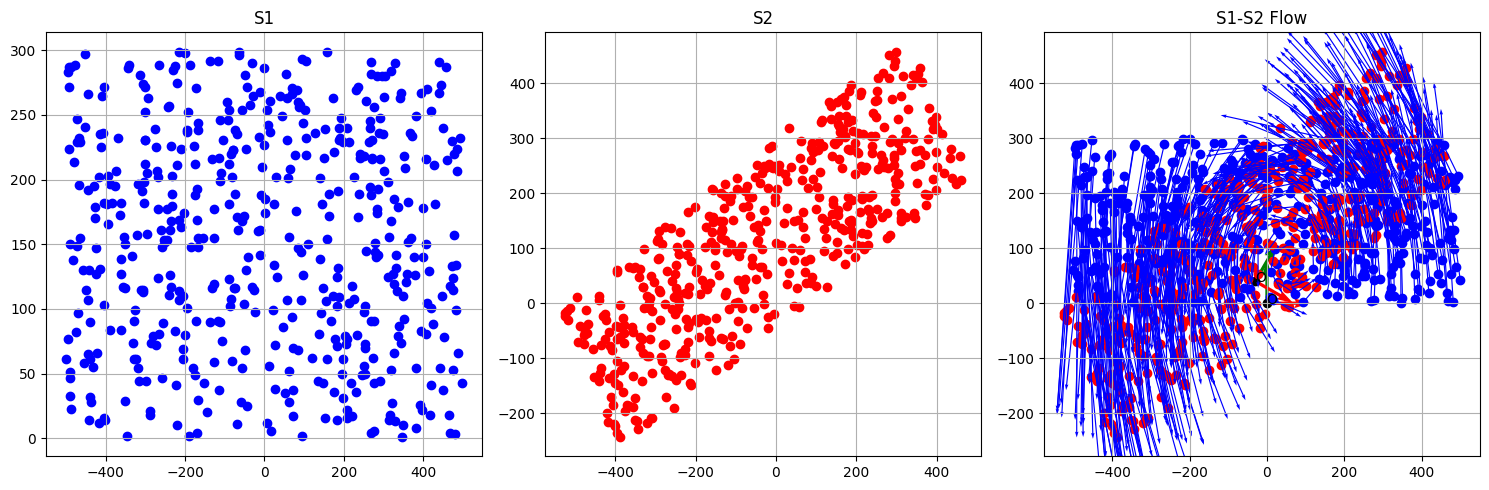

In [37]:
plt.figure(figsize=(15,5))

plt.subplot(1,3,1)
plt.title("S1")
plt.scatter(p_s1[:,0], p_s1[:,1], c='blue')
plt.grid()

plt.subplot(1,3,2)
plt.title("S2")
plt.scatter(p_s2[:,0], p_s2[:,1], c='red')
plt.grid()

plt.subplot(1,3,3)
plt.title("S1-S2 Flow")
draw_axes(np.eye(3))
draw_axes(T_s1_s2)
plt.scatter(p_s1[:,0], p_s1[:,1], c='blue')
plt.scatter(p_s2[:,0], p_s2[:,1], c='red')


plt.quiver(p_s1[:,0], p_s1[:,1],
           p_s2[:,0] - p_s1[:,0],
           p_s2[:,1] - p_s1[:,1],
           scale=500, color='blue', angles='xy')

plt.grid()

plt.tight_layout()
plt.show()

In [38]:
def compute_matrix(p_s1, p_s2):


    alpha = p_s2[:,1] / p_s2[:,0]
    beta  = p_s2[:,0] + np.square(p_s2[:,1])/p_s2[:,0]
    gamma = p_s1[:,1] - p_s2[:,1]/p_s2[:,0] * p_s1[:,0]

    A = np.array([[-alpha[i], 1, beta[i]] for i in range(len(alpha))])
    b = np.array(gamma)

    return A, b

In [39]:
def solve_pose(A : np.ndarray , b: np.ndarray):
    if A.shape[0] ==3 and A.shape[1] ==3: # inversion 
        x = np.linalg.inv(A) @ b
        x[2] = np.arcsin(x[2])
        return x
    else: # least squares (pseudo-inverse)
        x = np.linalg.inv(A.T @ A) @ A.T @ b
        x[2] = np.arcsin(x[2])
        return x

In [40]:
def compute_transform(dx, dy, dth):
    return np.array([[np.cos(dth), -np.sin(dth), dx], [np.sin(dth), np.cos(dth), dy], [0, 0, 1]])

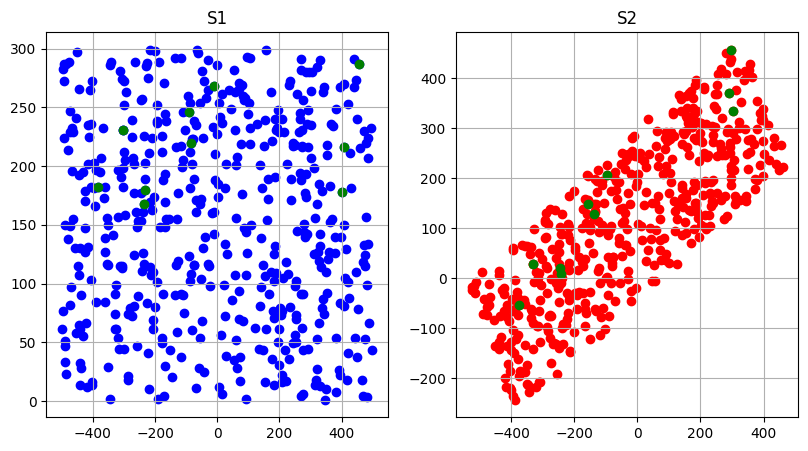

In [41]:
n_points = 10
rand_idx = np.random.choice(len(p_s1), n_points, replace=False)

p_s1_estim = np.array([p_s1[idx] for idx in rand_idx])
p_s2_estim = np.array([p_s2[idx] for idx in rand_idx])

plt.figure(figsize=(15,5))

plt.subplot(1,3,1)
plt.title("S1")
plt.scatter(p_s1[:,0], p_s1[:,1], c='blue')
plt.scatter(p_s1_estim[:,0], p_s1_estim[:,1], c='green')
plt.grid()

plt.subplot(1,3,2)
plt.title("S2")
plt.scatter(p_s2[:,0], p_s2[:,1], c='red')
plt.scatter(p_s2_estim[:,0], p_s2_estim[:,1], c='green')
plt.grid()

In [42]:

A, b = compute_matrix(p_s1_estim, p_s2_estim)
x_estim_wo_noise = solve_pose(A,b)

T_estim = compute_transform(x_estim_wo_noise[0], x_estim_wo_noise[1], x_estim_wo_noise[2])

In [43]:
print("T ground thruth: \n", T_s1_s2)
print("\nT estimated: \n",T_estim)

x_gt = np.array([dx, dy, dth])
x_err = x_gt - x_estim_wo_noise

print("\n---- ego motion estimation error ----\n")
print("dx error : ", x_err[0])
print("dy error : ", x_err[1])
print("dth error : ", x_err[2])

T ground thruth: 
 [[  0.8660254   0.5       -30.       ]
 [ -0.5         0.8660254  40.       ]
 [  0.          0.          1.       ]]

T estimated: 
 [[  0.8660254   0.5       -30.       ]
 [ -0.5         0.8660254  40.       ]
 [  0.          0.          1.       ]]

---- ego motion estimation error ----

dx error :  1.8474111129762605e-13
dy error :  -1.4210854715202004e-14
dth error :  2.220446049250313e-16


In [44]:
optical_flow = p_s2 - p_s1

corrupted_ratio = 0.4
corrupted_points = int(N_points * corrupted_ratio)
rand_idx = np.random.choice(len(p_s1), corrupted_points, replace=False)

# noise = np.random.normal(0.1 , 0.01, optical_flow.shape)
noise_magnitude = np.std(optical_flow) * 2
noise = np.random.normal(noise_magnitude, noise_magnitude * 0.5, optical_flow.shape)

optical_flow[rand_idx] = optical_flow[rand_idx] + noise[rand_idx]


In [45]:
print(corrupted_points)

200


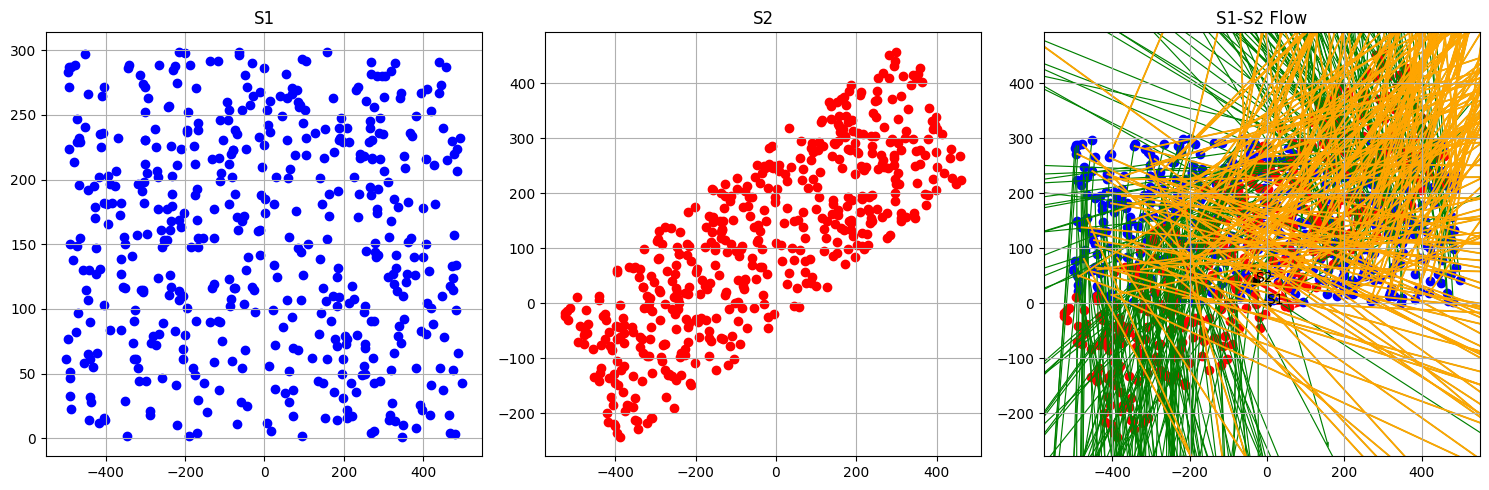

In [46]:
plt.figure(figsize=(15,5))

plt.subplot(1,3,1)
plt.title("S1")
plt.scatter(p_s1[:,0], p_s1[:,1], c='blue')
plt.grid()

plt.subplot(1,3,2)
plt.title("S2")
plt.scatter(p_s2[:,0], p_s2[:,1], c='red')
plt.grid()

plt.subplot(1,3,3)
plt.title("S1-S2 Flow")
draw_axes(np.eye(3), frame="S1")
draw_axes(T_s1_s2, frame="S2")
plt.scatter(p_s1[:,0], p_s1[:,1], c='blue')
plt.scatter(p_s2[:,0], p_s2[:,1], c='red')


plt.quiver(p_s1[:,0], p_s1[:,1],
           optical_flow[:,0],
           optical_flow[:,1],
           scale=40, color='green', angles='xy')
plt.quiver(p_s1[rand_idx,0], p_s1[rand_idx,1],
           optical_flow[rand_idx,0],
           optical_flow[rand_idx,1],
           scale=40, color='orange', angles='xy')

plt.grid()

plt.tight_layout()
plt.show()

In [47]:
n_points = 10
rand_idx = np.random.choice(len(p_s1), n_points, replace=False)

p_s1_estim = np.array([p_s1[idx] for idx in rand_idx])
p_s2_estim = np.array([p_s1[idx]+optical_flow[idx] for idx in rand_idx])

In [48]:
A, b = compute_matrix(p_s1_estim, p_s2_estim)
x_estim = solve_pose(A,b)

T_s1_s2_estim = compute_transform(x_estim[0], x_estim[1], x_estim[2])

In [49]:
print("T ground thruth: \n", T_s1_s2)
print("\nT estimated: \n",T_s1_s2_estim)

x_gt = np.array([dx, dy, dth])
x_err = x_gt - x_estim

print("\n---- ego motion estimation error ----\n")
print("dx error : ", x_err[0])
print("dy error : ", x_err[1])
print("dth error : ", x_err[2])

T ground thruth: 
 [[  0.8660254   0.5       -30.       ]
 [ -0.5         0.8660254  40.       ]
 [  0.          0.          1.       ]]

T estimated: 
 [[ 0.95115565  0.30871173 23.55520314]
 [-0.30871173  0.95115565 77.0892136 ]
 [ 0.          0.          1.        ]]

---- ego motion estimation error ----

dx error :  -53.55520314178141
dy error :  -37.08921360061831
dth error :  -0.20976047173804357


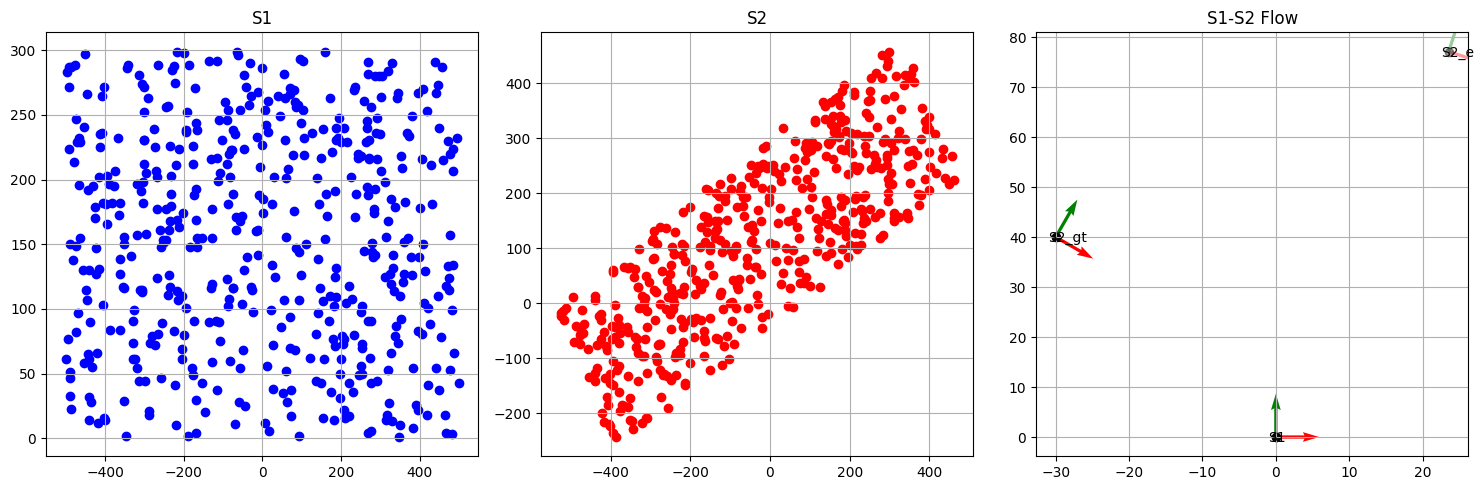

In [50]:
plt.figure(figsize=(15,5))

plt.subplot(1,3,1)
plt.title("S1")
plt.scatter(p_s1[:,0], p_s1[:,1], c='blue')
plt.grid()

plt.subplot(1,3,2)
plt.title("S2")
plt.scatter(p_s2[:,0], p_s2[:,1], c='red')
plt.grid()

plt.subplot(1,3,3)
plt.title("S1-S2 Flow")

draw_axes(np.eye(3), frame="S1")
draw_axes(T_s1_s2, frame="S2_gt")
draw_axes(T_s1_s2_estim, is_estimated=True, frame="S2_e")

# plt.scatter(p_s1[:,0], p_s1[:,1], c='blue')
# plt.scatter(p_s2[:,0], p_s2[:,1], c='red')


# plt.quiver(p_s1[:,0], p_s1[:,1],
#            optical_flow[:,0],
#            optical_flow[:,1],
#            scale=40, color='green', angles='xy')
# plt.quiver(p_s1[rand_idx,0], p_s1[rand_idx,1],
#            optical_flow[rand_idx,0],
#            optical_flow[rand_idx,1],
#            scale=40, color='orange', angles='xy')

plt.grid()

plt.tight_layout()
plt.show()

In [51]:
def measure_consensus(p_s1, inliers_idx, flow, T_s1_s2_estim, threshold):

    p_s1_tilde = np.hstack([p_s1, np.ones((len(p_s1), 1))]) 
    p_s2_tilde = (T_s1_s2_estim @ p_s1_tilde.T).T                 
    p_s2_estim = p_s2_tilde[:, :2]          

    estim_flow = np.zeros_like(flow)
    estim_flow = p_s2_estim - p_s1

    for idx in range(len(p_s1)):
        error = np.sqrt((flow[idx,0] - estim_flow[idx,0])**2 + (flow[idx,1] - estim_flow[idx,1])**2)
        if error < threshold: 
            inliers_idx = np.append(inliers_idx, idx)
            
    return inliers_idx

In [52]:
max_iter = 100
n_iter = 0
n_fit = 6
n_best_inliers = n_fit

inliers_best_idx = None
threshold = 1
p_s2 = np.zeros_like(p_s1)

while n_iter < max_iter:

    print("Iteration number: ", n_iter)

    # re-initialize inlier set
    inliers_idx = np.random.choice(len(p_s1), n_fit, replace=False)

    if inliers_best_idx is None: 
        inliers_best_idx = inliers_idx
        
    p_s2[inliers_idx] = p_s1[inliers_idx] + optical_flow[inliers_idx]

    A, b = compute_matrix(p_s1[inliers_idx], p_s2[inliers_idx])
    x = solve_pose(A, b)
    print("Current Estimate: tx = ", x[0], " ty = ", x[1], "theta = ", x[2])

    T_s1_s2_estim = np.linalg.inv(compute_transform(x[0], x[1], x[2]))
    inliers_idx = measure_consensus(p_s1, inliers_idx, optical_flow, T_s1_s2_estim, threshold)
    n_inliers = len(inliers_idx)

    print("Inliers Number: ", n_inliers)

    if n_inliers > n_best_inliers: 
        tx_best = x[0]
        ty_best = x[1]
        dtheta_best = x[2]
        print("Better Model Found, Inliers Number: ", n_inliers)
        inliers_best_idx = inliers_idx
        n_best_inliers = n_inliers

    n_iter += 1

p_s2_optim = p_s1[inliers_best_idx] + optical_flow[inliers_best_idx]
A_optim,b_optim = compute_matrix(p_s1[inliers_best_idx], p_s2_optim)
x_optim = solve_pose(A_optim, b_optim)
T_s1_s2_optim = compute_transform(x_optim[0], x_optim[1], x_optim[2])
print("Optimal Inliers Number: ", inliers_best_idx.shape[0])
print("Optimal Estimate: tx = ", x_optim[0], " ty = ", x_optim[1], "theta = ", x_optim[2])

Iteration number:  0
Current Estimate: tx =  -70.26843379735169  ty =  -34.796873153891724 theta =  -0.13108225640093307
Inliers Number:  6
Iteration number:  1
Current Estimate: tx =  -21.525137003780287  ty =  122.4801081259514 theta =  -0.20116953268585164
Inliers Number:  6
Iteration number:  2
Current Estimate: tx =  -53.38320787939225  ty =  -24.442892077382265 theta =  -0.3624303868407057
Inliers Number:  6
Iteration number:  3
Current Estimate: tx =  -376.78599120397996  ty =  -41.03518325924742 theta =  -0.9398240460825277
Inliers Number:  6
Iteration number:  4
Current Estimate: tx =  52.831694089783845  ty =  -23.168592148583546 theta =  -0.1767167124784035
Inliers Number:  6
Iteration number:  5
Current Estimate: tx =  -375.9273926970295  ty =  100.03100317693271 theta =  nan
Inliers Number:  6
Iteration number:  6
Current Estimate: tx =  -255.95338384711872  ty =  -67.64099053690327 theta =  -0.5798726556105284
Inliers Number:  6
Iteration number:  7
Current Estimate: tx =

/tmp/ipykernel_9570/210959041.py:8: RuntimeWarning: invalid value encountered in arcsin
  x[2] = np.arcsin(x[2])


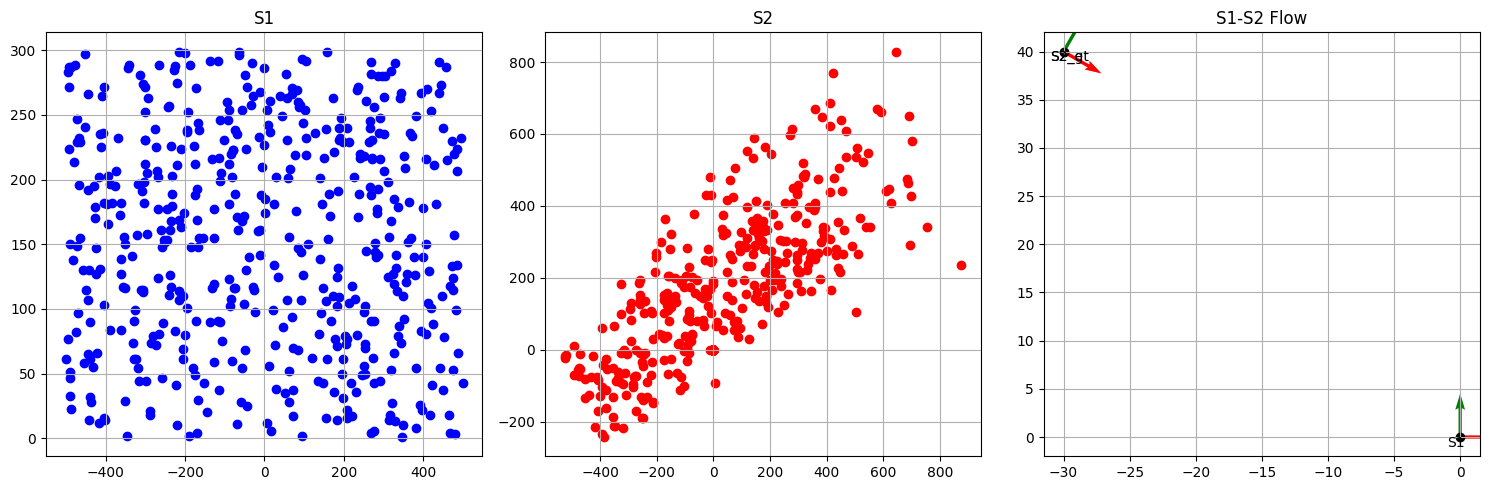

In [53]:
plt.figure(figsize=(15,5))

plt.subplot(1,3,1)
plt.title("S1")
plt.scatter(p_s1[:,0], p_s1[:,1], c='blue')
plt.grid()

plt.subplot(1,3,2)
plt.title("S2")
plt.scatter(p_s2[:,0], p_s2[:,1], c='red')
plt.grid()

plt.subplot(1,3,3)
plt.title("S1-S2 Flow")

draw_axes(np.eye(3), frame="S1")
draw_axes(T_s1_s2, frame="S2_gt")
draw_axes(T_s1_s2_optim, is_estimated=True, frame="S2_e")

# plt.scatter(p_s1[:,0], p_s1[:,1], c='blue')
# plt.scatter(p_s2[:,0], p_s2[:,1], c='red')


# plt.quiver(p_s1[:,0], p_s1[:,1],
#            optical_flow[:,0],
#            optical_flow[:,1],
#            scale=40, color='green', angles='xy')
# plt.quiver(p_s1[rand_idx,0], p_s1[rand_idx,1],
#            optical_flow[rand_idx,0],
#            optical_flow[rand_idx,1],
#            scale=40, color='orange', angles='xy')

plt.grid()

plt.tight_layout()
plt.show()

In [54]:
print("T ground thruth: \n", T_s1_s2)
print("\nT estimated: \n",T_s1_s2_optim)

x_gt = np.array([dx, dy, dth])
x_err = x_gt - x_optim

print("\n---- ego motion estimation error ----\n")
print("dx error : ", x_err[0])
print("dy error : ", x_err[1])
print("dth error : ", x_err[2])

T ground thruth: 
 [[  0.8660254   0.5       -30.       ]
 [ -0.5         0.8660254  40.       ]
 [  0.          0.          1.       ]]

T estimated: 
 [[  0.8660254   0.5       -30.       ]
 [ -0.5         0.8660254  40.       ]
 [  0.          0.          1.       ]]

---- ego motion estimation error ----

dx error :  -5.471179065352771e-13
dy error :  -7.105427357601002e-14
dth error :  -3.219646771412954e-15
